formula : C7H6O3
heavy   : 10
rotb    : 1
inchikey: FJKROLUGYXJWQN-UHFFFAOYSA-N


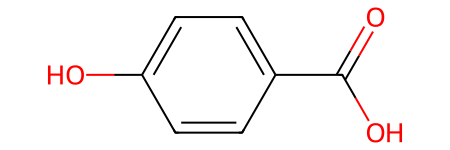

In [1]:
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolDescriptors
 
smiles = "OC(=O)c1ccc(O)cc1"     # paste yours exactly
mol = Chem.MolFromSmiles(smiles)
assert mol is not None, "SMILES did not parse: re-copy it from the menu"
 
print("formula :", rdMolDescriptors.CalcMolFormula(mol))
print("heavy   :", mol.GetNumHeavyAtoms())
print("rotb    :", rdMolDescriptors.CalcNumRotatableBonds(mol))
print("inchikey:", Chem.MolToInchiKey(mol))
mol                                   # last line of a cell: draws the structure

In [2]:
molH = Chem.AddHs(mol)
print(molH.GetNumAtoms())            # 20 for the example: 12 heavy + 8 H

16


In [3]:
params = AllChem.ETKDGv3()
params.randomSeed = 230970           # YOUR student ID number, digits only
params.pruneRmsThresh = -1           # keep every embedding; duplicates are removed after optimization (section 5)
cids = list(AllChem.EmbedMultipleConfs(molH, numConfs=100, params=params))
print(len(cids), "conformers embedded")

100 conformers embedded


In [4]:
assert AllChem.MMFFHasAllMoleculeParams(molH), "MMFF94 has no parameters for this molecule: see troubleshooting"
res = AllChem.MMFFOptimizeMoleculeConfs(molH, maxIters=2000)
# res is a list of (flag, energy) pairs, one per conformer, in cids order:
#   flag 0 converged, 1 not converged, -1 could not be set up (energy reported as -1.0)
 
energies = {cid: e for cid, (flag, e) in zip(cids, res) if flag == 0}
print(len(energies), "converged of", len(res))

100 converged of 100


In [5]:
from rdkit.Chem import rdMolAlign
from rdkit.Geometry import Point3D
 
def mirror_copy(m):
    mm = Chem.Mol(m)
    for conf in mm.GetConformers():
        for i in range(mm.GetNumAtoms()):
            p = conf.GetAtomPosition(i)
            conf.SetAtomPosition(i, Point3D(-p.x, p.y, p.z))
    return mm
 
achiral = len(Chem.FindMolChiralCenters(molH, includeUnassigned=True, useLegacyImplementation=False)) == 0
mirror = mirror_copy(molH) if achiral else None
 
distinct = []                        # one conformer id per distinct minimum, lowest energy first
for cid in sorted(energies, key=energies.get):
    same = any(rdMolAlign.GetBestRMS(molH, molH, cid, k) <= 0.3
               or (achiral and rdMolAlign.GetBestRMS(mirror, molH, cid, k) <= 0.3)
               for k in distinct)
    if not same:
        distinct.append(cid)
 
e0 = energies[distinct[0]]
survivors = [cid for cid in distinct if (energies[cid] - e0) * 4.184 <= 12.6]
print(len(distinct), "distinct minima,", len(survivors), "survivors within 12.6 kJ/mol")
for cid in distinct:
    print(f"conf {cid:3d}   {energies[cid]:9.3f} kcal/mol   {(energies[cid] - e0) * 4.184:6.2f} kJ/mol")

2 distinct minima, 2 survivors within 12.6 kJ/mol
conf  19       0.046 kcal/mol     0.00 kJ/mol
conf  74       0.152 kcal/mol     0.44 kJ/mol


In [6]:
from rdkit import Chem
from rdkit.Chem import Descriptors
import os

out_dir = "capstone 2"
os.makedirs(out_dir, exist_ok=True)

def orca_coords(m, cid):
    conf = m.GetConformer(cid)
    lines = [f"* xyz {Chem.GetFormalCharge(m)} {Descriptors.NumRadicalElectrons(m) + 1}"]
    for atom in m.GetAtoms():
        pos = conf.GetAtomPosition(atom.GetIdx())
        lines.append(f"{atom.GetSymbol():<2s} {pos.x:12.6f} {pos.y:12.6f} {pos.z:12.6f}")
    lines.append("*")
    return "\n".join(lines) + "\n"
 
def orca_input(m, cid, title):
    mult = Descriptors.NumRadicalElectrons(m) + 1
    ks = "! UKS B3LYP" if mult > 1 else "! B3LYP"     # open shell needs UKS, stated explicitly
    head = (f"# {title}\n{ks} 6-31+G(d,p) CPCM(Water) Opt Freq RIJCOSX def2/J\n"
            f"%pal nprocs 4 end\n%maxcore 3000\n%scf MaxIter 300 end\n")
    return head + orca_coords(m, cid)
 
for rank, cid in enumerate(survivors, 1):
    Chem.MolToXYZFile(molH, f"{out_dir}/conf{rank:02d}.xyz", confId=cid)        # for the visual check
    title = f"conf{rank:02d} seed 123456 MMFF94 {energies[cid]:.3f} kcal/mol"
    open(f"{out_dir}/conf{rank:02d}.inp", "w").write(orca_input(molH, cid, title))
 
print(orca_input(molH, survivors[0], "conf01 seed 230970"))

# conf01 seed 230970
! B3LYP 6-31+G(d,p) CPCM(Water) Opt Freq RIJCOSX def2/J
%pal nprocs 4 end
%maxcore 3000
%scf MaxIter 300 end
* xyz 0 1
O      3.097256    -0.189702    -0.451650
C      2.226180     0.762524    -0.074346
O      2.596350     1.894832     0.175525
C      0.828158     0.272499    -0.007468
C      0.488479    -1.051721    -0.312870
C     -0.843201    -1.465638    -0.235059
C     -1.827284    -0.559500     0.145923
O     -3.112360    -1.009445     0.207529
C     -1.505780     0.759325     0.452455
C     -0.174045     1.175540     0.375250
H      3.962873     0.269929    -0.451365
H      1.249819    -1.767814    -0.611637
H     -1.111617    -2.491869    -0.471005
H     -3.687555    -0.277228     0.484281
H     -2.268532     1.471941     0.750493
H      0.081259     2.206326     0.614265
*



In [7]:
# chiral centres: (atom index, "R"/"S", or "?" if unspecified)
print(Chem.FindMolChiralCenters(mol, includeUnassigned=True))
 
# double bonds with specified geometry
for b in mol.GetBonds():
    if b.GetStereo() != Chem.BondStereo.STEREONONE:
        print(b.GetBeginAtomIdx(), b.GetEndAtomIdx(), b.GetStereo())

[]


In [8]:
def search(seed):
    m = Chem.AddHs(Chem.MolFromSmiles(smiles))
    p = AllChem.ETKDGv3(); p.randomSeed = seed; p.pruneRmsThresh = -1
    c = list(AllChem.EmbedMultipleConfs(m, numConfs=20, params=p))
    r = AllChem.MMFFOptimizeMoleculeConfs(m, maxIters=2000)
    return sorted(round(e, 4) for f, e in r if f == 0)
 
print(search(11) == search(11))   # True: same seed, same answer
print(search(11) == search(12))   # False: different seed, different search

True
False
